# EDA - Agentes de IA e operações on-chain

**7º Datathon de Moedas Digitais FGV | Grupo 6 - Rio de Janeiro I**

Este notebook é a primeira etapa exploratória do tema **agentes de IA operando em ambientes on-chain**, com foco em stablecoins, governança e responsabilização. A análise foi preparada para receber um dataset de transações, ações de agentes e/ou eventos de governança sem antecipar conclusões que ainda não são sustentadas por dados.

> Estado atual: não há dataset no repositório. O notebook roda em modo de diagnóstico e fica pronto para analisar CSV, Parquet ou JSON colocado em `data/`.

## 1. Pergunta de pesquisa e hipóteses testáveis

### Pergunta provisória

Como agentes de IA que executam ou recomendam operações on-chain alteram o perfil de atividade, risco e responsabilização em protocolos que movimentam stablecoins e participam de governança?

### Hipóteses para orientar a próxima etapa

1. **Automação e concentração:** agentes mais automatizados podem concentrar volume, número de operações ou poder de voto em poucas carteiras.
2. **Risco operacional:** falhas, reversões, custos de gas e interações com contratos não verificados podem se concentrar em determinados agentes, protocolos ou períodos.
3. **Responsabilização:** a capacidade de ligar uma ação a um agente, carteira, modelo, operador ou política de limites deve variar entre operações; maior rastreabilidade deve estar associada a menor ambiguidade após eventos adversos.
4. **Stablecoins e governança:** operações com stablecoins e votos de governança podem apresentar padrões temporais, de concentração e de coordenação diferentes dos demais fluxos.

Estas são hipóteses, não resultados. Serão revisadas após conhecermos a fonte, a cobertura temporal e a unidade de observação do dataset.

## 2. Dados necessários

A unidade ideal é uma **ação on-chain** ou um **evento de governança**, com timestamp e identificadores que permitam agrupar por agente, carteira, protocolo e ativo. O quadro abaixo serve como contrato de dados inicial. Os nomes não precisam ser exatamente estes: a célula de ingestão tenta reconhecer aliases comuns.

| Bloco | Campos desejáveis | Uso na EDA |
|---|---|---|
| Tempo e rede | `timestamp`, `chain`, `block_number` | sazonalidade, atraso, comparação entre redes |
| Identidade | `agent_id`, `wallet_from`, `wallet_to`, `operator_id` | rastreabilidade e concentração |
| Ação | `tx_hash`, `action_type`, `protocol`, `contract_address`, `method` | tipologia e grafo de interações |
| Valor e custo | `asset`, `amount`, `amount_usd`, `gas_usd` | volume, custo, stablecoins |
| Resultado | `success`, `status`, `error`, `reverted` | falhas e risco operacional |
| Governança | `proposal_id`, `vote`, `voting_power`, `delegated_power` | participação, concentração e coordenação |
| Responsabilização | `model_version`, `policy_id`, `approval_id`, `human_review`, `trigger` | auditabilidade e atribuição |

Se o dataset disponível tiver apenas preços/volumes de tokens, ele poderá apoiar contexto de mercado, mas não responderá sozinho à pergunta sobre agentes e responsabilização.

## Dataset incorporado: Ethereum Transactions for Fraud Detection

O primeiro dataset adicionado ao projeto está em `data/Ethereum-Transactions-for-Fraud-Detection/` e contém os arquivos `first_order_df.csv` e `second_order_df.csv`. A configuração atual do notebook usa o `first_order_df.csv`, que é o arquivo menor e adequado para a primeira rodada da EDA.

### Estrutura reconhecida

As colunas originais são `TxHash`, `BlockHeight`, `TimeStamp`, `From`, `To`, `Value` e `isError`. Elas são padronizadas pelo notebook como:

- `TxHash` → `tx_hash`
- `BlockHeight` → `block_number`
- `TimeStamp` → `timestamp`
- `From` → `wallet_from`
- `To` → `wallet_to`
- `Value` → `amount`
- `isError` → `is_error`

O timestamp é Unix em segundos e `Value` representa o valor nativo da transação na unidade fornecida pelo dataset; não deve ser interpretado automaticamente como USD.

### Resultados iniciais

- 254.973 transações no `first_order_df.csv`.
- Período observado: 30/11/2016 a 18/05/2019.
- 37.241 carteiras de origem.
- 13.392 carteiras de destino.
- 93,87% de transações bem-sucedidas.
- 6,13% de transações com erro ou reversão.
- 331 registros possuem carteira de destino ausente.

### O que este dataset permite analisar

Este dataset é adequado para estudar concentração por carteira, frequência e volume de transações, padrões temporais, distribuição de valores e falhas ou reversões de transações. Ele também pode servir como base para procurar padrões compatíveis com automação, embora não identifique diretamente bots ou agentes de IA.

### Limitações metodológicas

O dataset não contém, por si só, rótulo confiável de fraude, identificação de agente de IA, protocolo, token, valor em USD, gas, operador, versão de modelo ou política de decisão. Portanto, `isError` deve ser interpretado como falha ou reversão da transação, e não como fraude comprovada.

Também não é possível identificar stablecoins diretamente, pois não há coluna de ativo ou token. Para aproximar o projeto da pergunta sobre agentes on-chain, será necessário complementar estes dados com logs de contratos, rótulos de carteiras, preços, dados de gas, protocolos DeFi ou fontes de governança.

In [23]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
try:
    import matplotlib.pyplot as plt
    plt.style.use('seaborn-v0_8-whitegrid')
    HAS_PLOTTING = True
except ImportError:
    HAS_PLOTTING = False

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 100)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT / 'data'
DATA_DIR.mkdir(exist_ok=True)
print(f'Raiz do projeto: {ROOT}')
print(f'Diretório de dados: {DATA_DIR}')

Raiz do projeto: /Users/antonio/Documents/kognilabs/analytica/moedas-digitais-g6
Diretório de dados: /Users/antonio/Documents/kognilabs/analytica/moedas-digitais-g6/data


In [24]:
# Ingestão flexível: por padrão, usa o arquivo menor/principal do dataset.
# Para escolher manualmente, defina DATA_FILE com um caminho relativo a data/.
# Exemplo: DATA_FILE = 'Ethereum-Transactions-for-Fraud-Detection/second_order_df.csv'
DATA_FILE = 'Ethereum-Transactions-for-Fraud-Detection/first_order_df.csv'
SUPPORTED = {'.csv', '.parquet', '.json', '.jsonl'}
files = sorted(p for p in DATA_DIR.rglob('*') if p.is_file() and p.suffix.lower() in SUPPORTED)

def read_table(path):
    suffix = path.suffix.lower()
    if suffix == '.csv':
        return pd.read_csv(path, low_memory=False)
    if suffix == '.parquet':
        return pd.read_parquet(path)
    if suffix in {'.json', '.jsonl'}:
        return pd.read_json(path, lines=(suffix == '.jsonl'))
    raise ValueError(f'Formato não suportado: {suffix}')

if DATA_FILE is not None:
    path = DATA_DIR / DATA_FILE
    if not path.exists():
        raise FileNotFoundError(f'Arquivo não encontrado: {path}')
    files = [path]

if files:
    DATA_PATH = files[0]
    df_raw = read_table(DATA_PATH)
    print(f'Arquivo selecionado: {DATA_PATH.relative_to(ROOT)}')
    print(f'Dimensões: {df_raw.shape[0]:,} linhas x {df_raw.shape[1]:,} colunas')
    display(df_raw.head())
else:
    DATA_PATH = None
    df_raw = pd.DataFrame()
    print('Nenhum CSV, Parquet ou JSON foi encontrado em data/.')
    print('Próximo passo: adicionar o dataset em data/ e executar novamente esta célula.')

Arquivo selecionado: data/Ethereum-Transactions-for-Fraud-Detection/first_order_df.csv
Dimensões: 254,973 linhas x 8 colunas


,Unnamed: 0,TxHash,BlockHeight,TimeStamp,From,To,Value,isError
0,0,0xaca3850ba0080cf47b47f80e46da452f61bcbb5470d3...,5848095,1529873859,0x16f209b5332a1b4fa5bf19497ca40154c5db2f85,0x002f0c8119c16d310342d869ca8bf6ace34d9c39,0.500000,0
1,1,0x95681862f9778e49caecf603dd911d6ed57f7799d89d...,5848181,1529875104,0xe7e07e44ee315b5f2d076340b2b7a5cc9a4ee57b,0x002f0c8119c16d310342d869ca8bf6ace34d9c39,0.001020,0
2,2,0x716ae3961b50186a0bbc272cfcc4555662f7fe33550f...,5848716,1529883192,0x002f0c8119c16d310342d869ca8bf6ace34d9c39,0xe892875b87b94c44edf0e91ee9f49d0525fadd83,0.500390,0
3,3,0xf397197b800d6cc055a4db265b5e9df3dd2aa745c813...,5849038,1529887684,0x0681d8db095565fe8a346fa0277bffde9c0edbbf,0x002f0c8119c16d310342d869ca8bf6ace34d9c39,0.817800,0
4,4,0x7f8086011a32f128dba57fe06fc5f4a181d2f5401e5a...,5849437,1529893144,0x002f0c8119c16d310342d869ca8bf6ace34d9c39,0xe892875b87b94c44edf0e91ee9f49d0525fadd83,0.817506,0


In [25]:
# Padronização de nomes e reconhecimento de aliases.
def clean_name(name):
    name = str(name).strip().lower()
    name = re.sub(r'[^a-z0-9]+', '_', name).strip('_')
    return name

ALIASES = {
    'timestamp': ['timestamp', 'datetime', 'date', 'time', 'block_timestamp', 'time_stamp'],
    'chain': ['chain', 'network', 'blockchain'],
    'tx_hash': ['tx_hash', 'txhash', 'transaction_hash', 'hash', 'transaction'],
    'block_number': ['block_number', 'blockheight', 'block_height', 'block'],
    'agent_id': ['agent_id', 'agent', 'bot_id', 'model_id', 'strategy_id'],
    'wallet_from': ['wallet_from', 'from', 'sender', 'address_from', 'source'],
    'wallet_to': ['wallet_to', 'to', 'receiver', 'address_to', 'destination'],
    'action_type': ['action_type', 'action', 'operation', 'event_type', 'type'],
    'protocol': ['protocol', 'project', 'platform', 'dapp'],
    'asset': ['asset', 'token', 'symbol', 'coin', 'currency'],
    'amount': ['amount', 'value', 'token_amount', 'quantity'],
    'amount_usd': ['amount_usd', 'value_usd', 'usd_value', 'volume_usd', 'notional_usd'],
    'gas_usd': ['gas_usd', 'fee_usd', 'transaction_fee_usd'],
    'success': ['success', 'succeeded', 'status', 'result'],
    'is_error': ['is_error', 'iserror', 'error', 'transaction_error'],
    'proposal_id': ['proposal_id', 'proposal', 'governance_proposal'],
    'vote': ['vote', 'voting_choice', 'choice'],
    'voting_power': ['voting_power', 'votes', 'delegated_power'],
    'human_review': ['human_review', 'human_approval', 'manual_review'],
    'model_version': ['model_version', 'model', 'llm_version'],
    'policy_id': ['policy_id', 'policy', 'rule_id'],
}

def canonicalize(df):
    out = df.copy()
    out.columns = [clean_name(c) for c in out.columns]
    rename = {}
    for canonical, aliases in ALIASES.items():
        for alias in aliases:
            alias = clean_name(alias)
            if alias in out.columns and canonical not in out.columns:
                rename[alias] = canonical
                break
    return out.rename(columns=rename), rename

df, rename_map = canonicalize(df_raw)
if not df.empty:
    print('Colunas reconhecidas:', rename_map or 'nenhuma')
    print('Colunas disponíveis:', list(df.columns))
else:
    print('Aguardando dataset para padronização.')

Colunas reconhecidas: {'txhash': 'tx_hash', 'blockheight': 'block_number', 'from': 'wallet_from', 'to': 'wallet_to', 'value': 'amount', 'iserror': 'is_error'}
Colunas disponíveis: ['unnamed_0', 'tx_hash', 'block_number', 'timestamp', 'wallet_from', 'wallet_to', 'amount', 'is_error']


In [26]:
# Diagnóstico inicial de completude, tipos e duplicidade.
if df.empty:
    print('Diagnóstico não executado: o dataset ainda não foi carregado.')
else:
    profile = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'n_unique': df.nunique(dropna=True),
        'missing_n': df.isna().sum(),
        'missing_pct': (df.isna().mean() * 100).round(2),
    }).sort_values(['missing_pct', 'n_unique'], ascending=[False, True])
    print(f'Linhas duplicadas completas: {df.duplicated().sum():,} ({df.duplicated().mean():.2%})')
    display(profile)
    if 'timestamp' in df.columns:
        # Este dataset fornece Unix timestamp em segundos.
        timestamp_numeric = pd.to_numeric(df['timestamp'], errors='coerce')
        if timestamp_numeric.notna().mean() > 0.8:
            df['timestamp'] = pd.to_datetime(timestamp_numeric, unit='s', errors='coerce', utc=True)
        else:
            df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce', utc=True)
        print('Período:', df['timestamp'].min(), 'até', df['timestamp'].max())
        print('Timestamps inválidos:', df['timestamp'].isna().sum())

Linhas duplicadas completas: 0 (0.00%)


,dtype,n_unique,missing_n,missing_pct
wallet_to,str,13392,331,0.13
is_error,int64,2,0,0.00
amount,float64,32290,0,0.00
wallet_from,str,37241,0,0.00
block_number,int64,85874,0,0.00
timestamp,int64,85874,0,0.00
tx_hash,str,102149,0,0.00
unnamed_0,int64,254973,0,0.00


Período: 2016-11-30 15:47:25+00:00 até 2019-05-18 01:10:36+00:00
Timestamps inválidos: 0


In [27]:
# Métricas derivadas para atividade, custo e responsabilização.
def as_numeric(frame, column):
    if column in frame.columns:
        frame[column] = pd.to_numeric(frame[column], errors='coerce')

if not df.empty:
    for col in ['amount', 'amount_usd', 'gas_usd', 'voting_power']:
        as_numeric(df, col)
    if 'is_error' in df.columns:
        error_text = df['is_error'].astype(str).str.lower().str.strip()
        error_flag = pd.to_numeric(df['is_error'], errors='coerce')
        error_flag = error_flag.where(error_flag.notna(), error_text.map({'true': 1, 'yes': 1, 'error': 1, 'false': 0, 'no': 0}))
        df['error_flag'] = error_flag
        df['success_flag'] = 1 - df['error_flag']
    elif 'success' in df.columns:
        success_text = df['success'].astype(str).str.lower().str.strip()
        df['success_flag'] = success_text.map({'true': 1, '1': 1, 'yes': 1, 'success': 1, 'successful': 1, 'false': 0, '0': 0, 'no': 0, 'failed': 0, 'failure': 0})
    identity_cols = [c for c in ['agent_id', 'wallet_from', 'operator_id', 'model_version', 'policy_id'] if c in df.columns]
    df['accountability_fields_present'] = df[identity_cols].notna().sum(axis=1) if identity_cols else 0
    if 'asset' in df.columns:
        df['is_stablecoin'] = df['asset'].astype(str).str.upper().isin({'USDT', 'USDC', 'DAI', 'FDUSD', 'USDE', 'PYUSD', 'TUSD'})
    if 'timestamp' in df.columns:
        df['date'] = df['timestamp'].dt.floor('D')
        df['hour'] = df['timestamp'].dt.hour
    print('Métricas adicionadas:', [c for c in ['error_flag', 'success_flag', 'accountability_fields_present', 'is_stablecoin', 'date', 'hour'] if c in df.columns])
else:
    print('Métricas derivadas serão calculadas assim que o dataset for carregado.')

Métricas adicionadas: ['error_flag', 'success_flag', 'accountability_fields_present', 'date', 'hour']


,n_operations,amount
date,,
2016-11-30 00:00:00+00:00,9,2084.079246
2017-03-04 00:00:00+00:00,3,15.497101
2017-03-05 00:00:00+00:00,9,170.953774
2017-05-20 00:00:00+00:00,18,0.020000
2017-05-27 00:00:00+00:00,15,0.157226


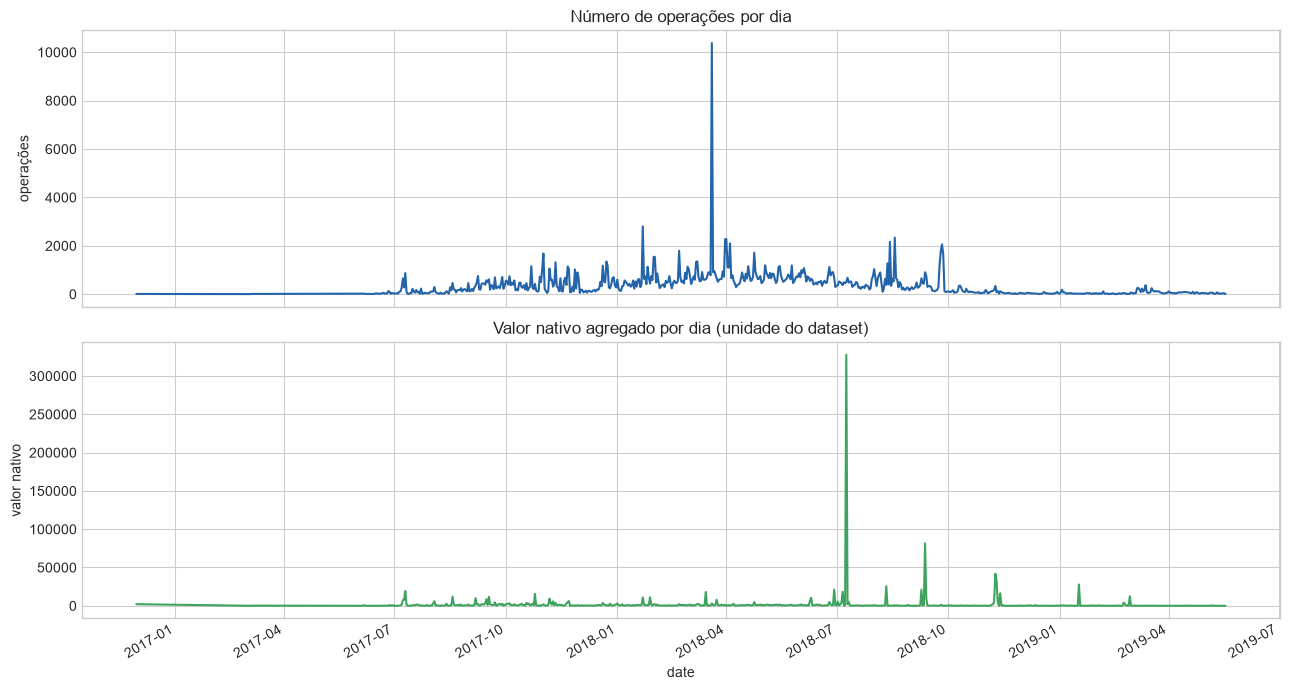

In [28]:
# Visão de atividade ao longo do tempo.
if df.empty or 'date' not in df.columns:
    print('Gráfico temporal indisponível: é necessário timestamp.')
elif not HAS_PLOTTING:
    print('Gráfico temporal não gerado: instale matplotlib para habilitar visualizações.')
else:
    daily = df.groupby('date').size().rename('n_operations').to_frame()
    value_col = 'amount_usd' if 'amount_usd' in df.columns else ('amount' if 'amount' in df.columns else None)
    if value_col is not None:
        daily = daily.join(df.groupby('date')[value_col].sum().rename(value_col))
    display(daily.head())
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    daily['n_operations'].plot(ax=axes[0], color='#2364aa', title='Número de operações por dia')
    axes[0].set_ylabel('operações')
    if 'amount_usd' in daily.columns:
        daily['amount_usd'].plot(ax=axes[1], color='#3da35d', title='Valor agregado por dia (USD)')
        axes[1].set_ylabel('USD')
    elif 'amount' in daily.columns:
        daily['amount'].plot(ax=axes[1], color='#3da35d', title='Valor nativo agregado por dia (unidade do dataset)')
        axes[1].set_ylabel('valor nativo')
    else:
        axes[1].text(0.5, 0.5, 'amount_usd não disponível', ha='center', va='center')
        axes[1].set_axis_off()
    plt.tight_layout()
    plt.show()

,n_operations,amount
wallet_from,,
0xc2d7cf95645d33006175b78989035c7c9061d3f9,8744,1.040040
0xf7c00dea37f797bb83cbf4655d87f3449953004e,3588,0.856228
0xb547027a4ccd46ec98199fa88aaedf5aa981db26,3546,301.854701
0x21f74c6bbc1e3ab9f0205e12de3a9daa14351aed,2490,2752.326261
0x3f5ce5fbfe3e9af3971dd833d26ba9b5c936f0be,2397,4823.264425
0xbfa82fbe0e66d8e2b7dcc16328db9ecd70533d13,2241,11.915642
0x6aef2850c2ce2ef583ae8a36be3357080608bdc3,2166,4618.161441
0x3cbd2e6143f057bd49ffb4c7058217a5900c35d3,2052,1798.898237
0xfbb1b73c4f0bda4f67dca266ce6ef42f520fbb98,1965,2664.011456


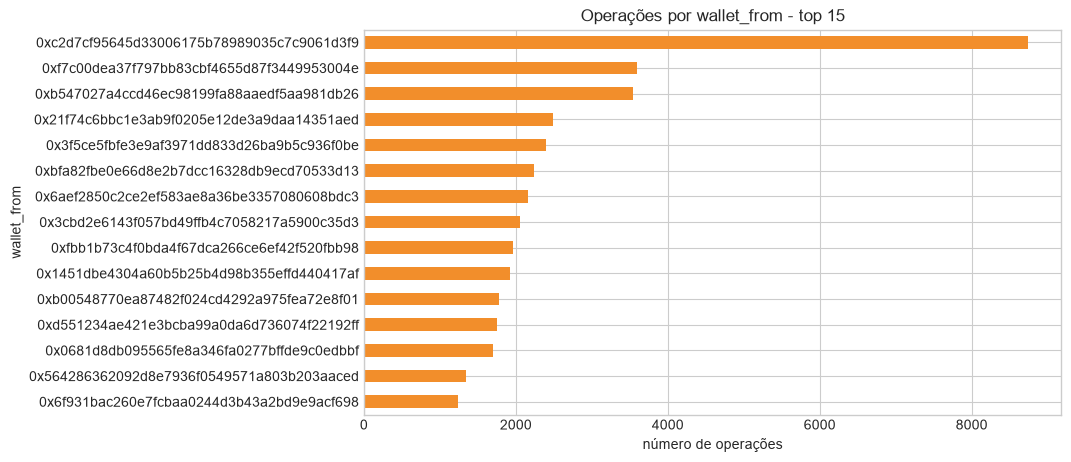

Stablecoin não identificável: o dataset não contém coluna de ativo/token.


In [29]:
# Concentração por agente/carteira/protocolo e uso de stablecoins.
if df.empty:
    print('Análise de concentração indisponível sem dataset.')
elif not HAS_PLOTTING:
    print('Análise tabular disponível, mas gráfico não gerado: instale matplotlib para habilitar visualizações.')
else:
    group_col = next((c for c in ['agent_id', 'wallet_from', 'operator_id'] if c in df.columns), None)
    if group_col:
        concentration = df[group_col].value_counts(dropna=False).head(15).rename('n_operations').to_frame()
        value_col = 'amount_usd' if 'amount_usd' in df.columns else ('amount' if 'amount' in df.columns else None)
        if value_col is not None:
            concentration[value_col] = df.groupby(group_col)[value_col].sum().reindex(concentration.index)
        display(concentration)
        concentration['n_operations'].sort_values().plot.barh(figsize=(9, 5), color='#f28e2b', title=f'Operações por {group_col} - top 15')
        plt.xlabel('número de operações')
        plt.show()
    else:
        print('Não foi encontrada uma coluna de agente/carteira para medir concentração.')
    if 'is_stablecoin' in df.columns:
        print(f'Participação de linhas com stablecoin: {df["is_stablecoin"].mean():.2%}')
        display(df.groupby('is_stablecoin').size().rename('n_operations').to_frame())
    else:
        print('Stablecoin não identificável: o dataset não contém coluna de ativo/token.')

In [30]:
# Falhas, custos e sinais de responsabilização.
if df.empty:
    print('Análise de risco e responsabilização indisponível sem dataset.')
else:
    summary = {}
    if 'success_flag' in df.columns:
        summary['taxa_sucesso'] = df['success_flag'].mean()
        summary['n_status_validos'] = df['success_flag'].notna().sum()
    if 'gas_usd' in df.columns:
        summary['gas_usd_mediano'] = df['gas_usd'].median()
        summary['gas_usd_total'] = df['gas_usd'].sum()
    if 'accountability_fields_present' in df.columns:
        summary['rastreabilidade_media_campos'] = df['accountability_fields_present'].mean()
        summary['linhas_sem_identificador'] = (df['accountability_fields_present'] == 0).mean()
    display(pd.Series(summary, name='valor').to_frame())
    available = [c for c in ['success_flag', 'gas_usd', 'accountability_fields_present'] if c in df.columns]
    if available:
        display(df[available].describe().T)
    else:
        print('O dataset ainda não contém campos reconhecidos para risco ou responsabilização.')

,valor
taxa_sucesso,0.938684
n_status_validos,254973.000000
rastreabilidade_media_campos,1.000000
linhas_sem_identificador,0.000000


,count,mean,std,min,25%,50%,75%,max
success_flag,254973.0,0.938684,0.23991,0.0,1.0,1.0,1.0,1.0
accountability_fields_present,254973.0,1.000000,0.00000,1.0,1.0,1.0,1.0,1.0


## 3. Limitações e próximo passo de dados

Sem dados de ações de agentes, esta EDA não pode estimar concentração, falhas, coordenação ou responsabilização. O próximo passo é escolher uma fonte com cobertura e licença adequadas. A ordem recomendada é:

1. Definir se o objeto será **transação executada**, **decisão/recomendação de agente**, **voto de governança** ou uma combinação dessas tabelas.
2. Selecionar uma rede e janela temporal gerenciáveis; começar com Ethereum ou uma rede EVM com dados públicos.
3. Obter eventos via dataset indexado/API (por exemplo, Dune, Flipside, Google BigQuery public crypto datasets, Etherscan ou RPC), verificando limites, licença e reprodutibilidade.
4. Construir uma tabela de ligação entre `tx_hash`, carteira, contrato, agente/operador e evidência de autorização.
5. Só então complementar com preço de stablecoins, eventos de governança e contexto regulatório.

### Critério de decisão

Se não for possível observar agentes ou evidências de automação, devemos reformular o projeto para uma pergunta observável, como concentração e falhas de operações de stablecoins ou participação em governança. Isso preserva a honestidade metodológica e pode resultar em uma solução mais forte do que atribuir IA a carteiras sem evidência.

## 4. Checklist para a próxima reunião do grupo

- [ ] Confirmar se o grupo quer manter agentes de IA como foco principal.
- [ ] Escolher a unidade de observação e uma rede inicial.
- [ ] Confirmar se alguém tem acesso a Dune, Flipside, BigQuery, RPC ou outra fonte indexada.
- [ ] Definir o que será considerado evidência de agente/autonomia, para não confundir bot, multisig, automação simples e agente de IA.
- [ ] Adicionar o primeiro arquivo em `data/` e executar novamente as células de ingestão e EDA.
- [ ] Registrar fonte, data de extração, filtros, licença e limitações para a futura apresentação de até 10 slides.